# Samuel — Classification Round 2

Hybrid Robustness · Missing Stream · Threshold Stability

## tl;dr

Pada fixed threshold 0,50, **C4_HGB** memimpin primary Macro F1 **0.8255**; **C4_HGB** memimpin pooled H12 **0.7968**. C2-B original memberi **0.8206 / 0.7886**.

Routing memperbaiki missing-stream sambil mempertahankan present predictions pada cutoff tetap. Indicator ablation dan dua text weights belum memperbaiki single hybrid secara konsisten. Threshold alternatives mempunyai trade-off; belum ada policy universal atau final model.

## Context & Methods

Target `artifact_signal`, metric **Macro F1** dengan labels [0,1]. Round 1 adalah checkpoint yang dipertahankan, termasuk source dan saved probabilities. Empat controls, empat ablations/weights, dua availability routes; bukan ensemble search. Seed42, LR C=1/liblinear, seluruh preprocessing/TF-IDF fit-only seperti Round1.

### Key Assumptions

**Adaptive development validation:** Round 2 dirancang dari outcome Round 1 pada cycle yang sama. Freeze tidak membuat validation menjadi untouched. H12 memakai ulang records primary dan bukan evidence independen. Timing rinci fitur masih provisional; tidak ada Test prediction atau leaderboard optimization. Pertanyaan EDA formal Samuel tetap Regression.

Protokol dibekukan sebelum diagnosis saved-vector dan seluruh 72 fit baru. Threshold/gate tidak dipilih dari outer labels. Source lama hanya dibaca; reports/notebook Round1 tidak dijalankan ulang.

In [1]:
from pathlib import Path
import sys,json,io,contextlib
import pandas as pd
from IPython.display import display,Image

ROOT=Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').is_file() and ROOT!=ROOT.parent: ROOT=ROOT.parent
if not (ROOT/'src/utils/paths.py').is_file(): raise FileNotFoundError('Open inside TP2 repository.')
sys.path.insert(0,str(ROOT))
from src.models.classification_round2_evaluation import verify_freeze,load_protocol,run_round2
from src.models.classification_round2_reporting import build_round2_report
from scripts.verify_classification_round2 import verify_results
from scripts.analyze_classification_round2 import analyze_round2
freeze=verify_freeze();protocol=load_protocol();path=ROOT/'reports/classification_round2/results.json'
ready=False
if path.exists():
    old=json.loads(path.read_text(encoding='utf-8'));artifact=ROOT/'experiments/runs'/old['run_id']
    ready=old['status']=='CLASSIFICATION_ROUND2_COMPLETE_REVIEW_NO_FINAL_MODEL' and all(
        (artifact/f'fit{end}__{m}.npz').is_file() and (artifact/f'fit{end}__{m}.json').is_file()
        for end in old['unique_outer_histories'] for m in protocol['fit_recipes'])
if not ready:
    print('Rebuilding frozen Round2 cache; baseline dependencies reconstruct only in Round2 namespace if needed.')
    with contextlib.redirect_stdout(io.StringIO()):run_round2(bootstrap=True)
results=json.loads(path.read_text(encoding='utf-8'))
verification=verify_results(); behavior=analyze_round2(); report_paths=build_round2_report()
P=results['aggregate']['primary'];H=results['aggregate']['secondary']
FIG=ROOT/'reports/classification_round2/figures'
models=[r['id'] for r in protocol['recipes']]
print(results['status'],results['total_evaluation_jobs'],'jobs')
print('Freeze:',freeze['signature'])
print('Independent verification:',verification['status'])

CLASSIFICATION_ROUND2_COMPLETE_REVIEW_NO_FINAL_MODEL 80 jobs
Freeze: edefbb8db8852f8000a854c54ade58b9eb66468af0f92acf8ad66d0b2572f3e1
Independent verification: PASS


## Data dan validation

Gunakan official Train yang sama: 50.608 rows; primary validation mencakup 38.588 unique rows pada 24 cycle 56–79. Raw tidak diubah. Train/test review dan target prevalence tetap merujuk `reports/classification_round1/data_review.json`.

W1/H12_E dan W4/H12_L berbagi fit. Enam histories menghasilkan 24 control outer refits +24 variant outer fits +24 variant inner fits. Control inner probabilities dipakai ulang. Routes tidak melatih model/gate. Diagnosis pertama memakai saved OOF probabilities; fresh routed outputs harus cocok identik.

In [2]:
display(pd.DataFrame([{'family':family,**w} for family,key in [('primary','primary_windows'),('secondary','secondary_windows')] for w in protocol[key]]))
display(pd.DataFrame([{'recipe':r['id'],'kind':r['kind'],'change':r['description']} for r in protocol['recipes']]))
print('Fresh estimator fits:',results['fresh_model_fits_this_run'])
print('Saved-vs-fresh routing check:',results['routing_diagnostic_comparison'])

,family,id,fit,validation
0,primary,W1,"[47, 55]","[56, 59]"
1,primary,W2,"[47, 59]","[60, 63]"
2,primary,W3,"[47, 63]","[64, 67]"
3,primary,W4,"[47, 67]","[68, 71]"
4,primary,W5,"[47, 71]","[72, 75]"
5,primary,W6,"[47, 75]","[76, 79]"
6,secondary,H12_E,"[47, 55]","[56, 67]"
7,secondary,H12_L,"[47, 67]","[68, 79]"


,recipe,kind,change
0,C1_A,control,"Unmodified Round1 control, fresh outer refit; ..."
1,C1_B,control,"Unmodified Round1 control, fresh outer refit; ..."
2,C2_A,control,"Unmodified Round1 control, fresh outer refit; ..."
3,C2_B,control,"Unmodified Round1 control, fresh outer refit; ..."
4,C3_B,variant,C1_A plus explicit missing-stream indicator; a...
5,C3_C,variant,C2_B minus explicit missing-stream indicator
6,C5_LOW,variant,C2_B with TFIDF block multiplied by0.5 atfit/p...
7,C5_HIGH,variant,C2_B with TFIDF block multiplied by2.0 atfit/p...
8,C4_LR,route,Fixed availability route; one pooled inner thr...
9,C4_HGB,route,Fixed availability route; one pooled inner thr...


Fresh estimator fits: 72
Saved-vs-fresh routing check: {'status': 'PASS', 'window_vectors_identical': 24, 'route_window_vectors': 16, 'hybrid_control_window_vectors': 8}


## Results — semua kandidat pada kontrol fixed 0,50

Pooled F1 dihitung dari seluruh prediksi gabungan, bukan rata-rata subgroup/window F1. Equal-cycle adalah mean F1 setiap cycle. AP/Brier memakai probabilitas dan tidak bergantung cutoff. H12 dilaporkan terpisah.

,recipe,primary F1,equal-cycle F1,H12 F1,AP primary,Brier primary
0,C1_A,0.7145,0.7121,0.6768,0.6734,0.1690
1,C1_B,0.7310,0.7262,0.6891,0.7086,0.1593
2,C2_A,0.8014,0.7916,0.7819,0.8181,0.1259
3,C2_B,0.8206,0.8124,0.7886,0.8276,0.1187
4,C3_B,0.7145,0.7121,0.6771,0.6734,0.1690
5,C3_C,0.8194,0.8107,0.7870,0.8268,0.1193
6,C5_LOW,0.8092,0.8014,0.7755,0.8109,0.1252
7,C5_HIGH,0.8191,0.8116,0.7894,0.8273,0.1197
8,C4_LR,0.8242,0.8173,0.7945,0.8274,0.1181
9,C4_HGB,0.8255,0.8183,0.7968,0.8293,0.1172


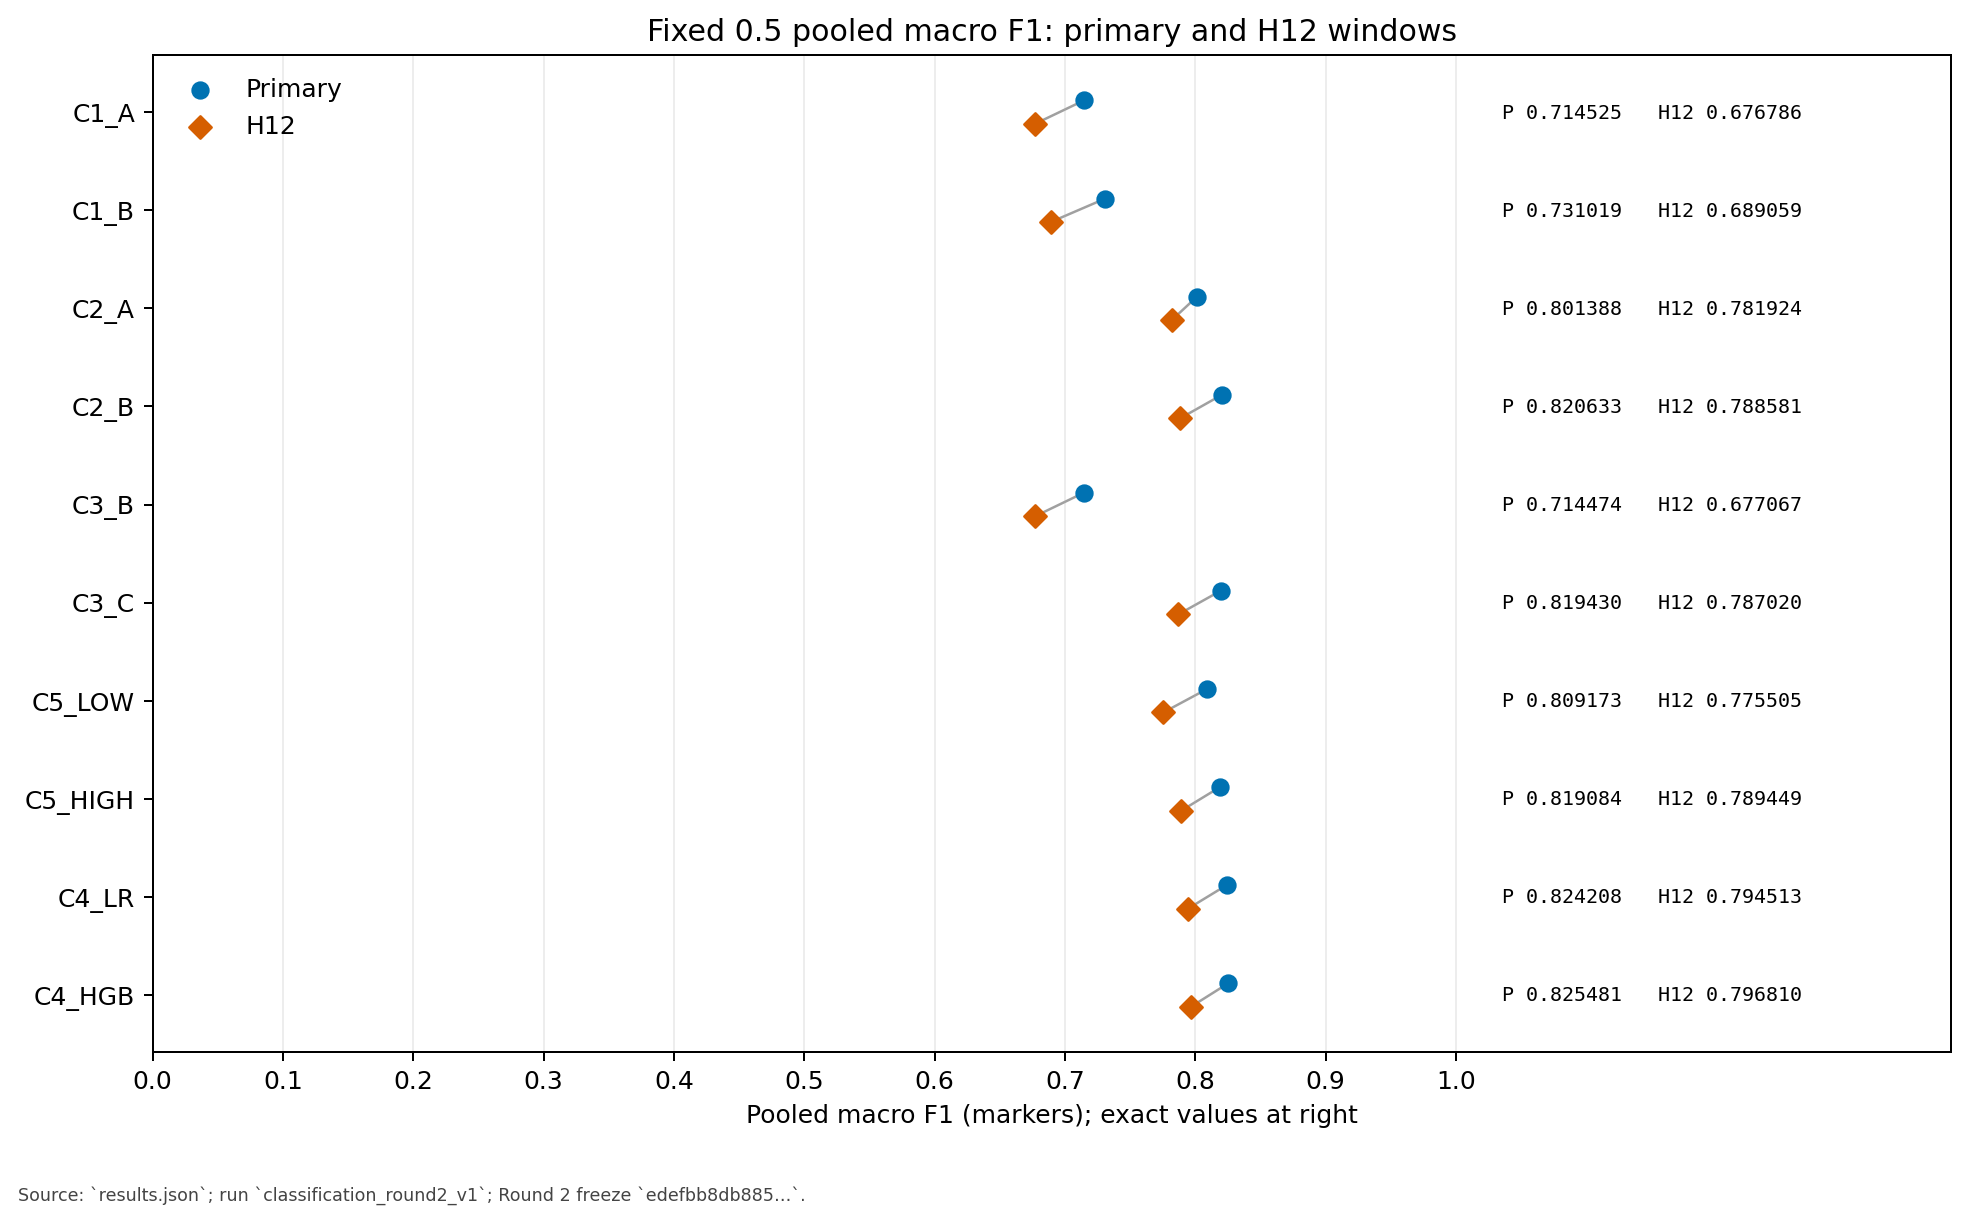

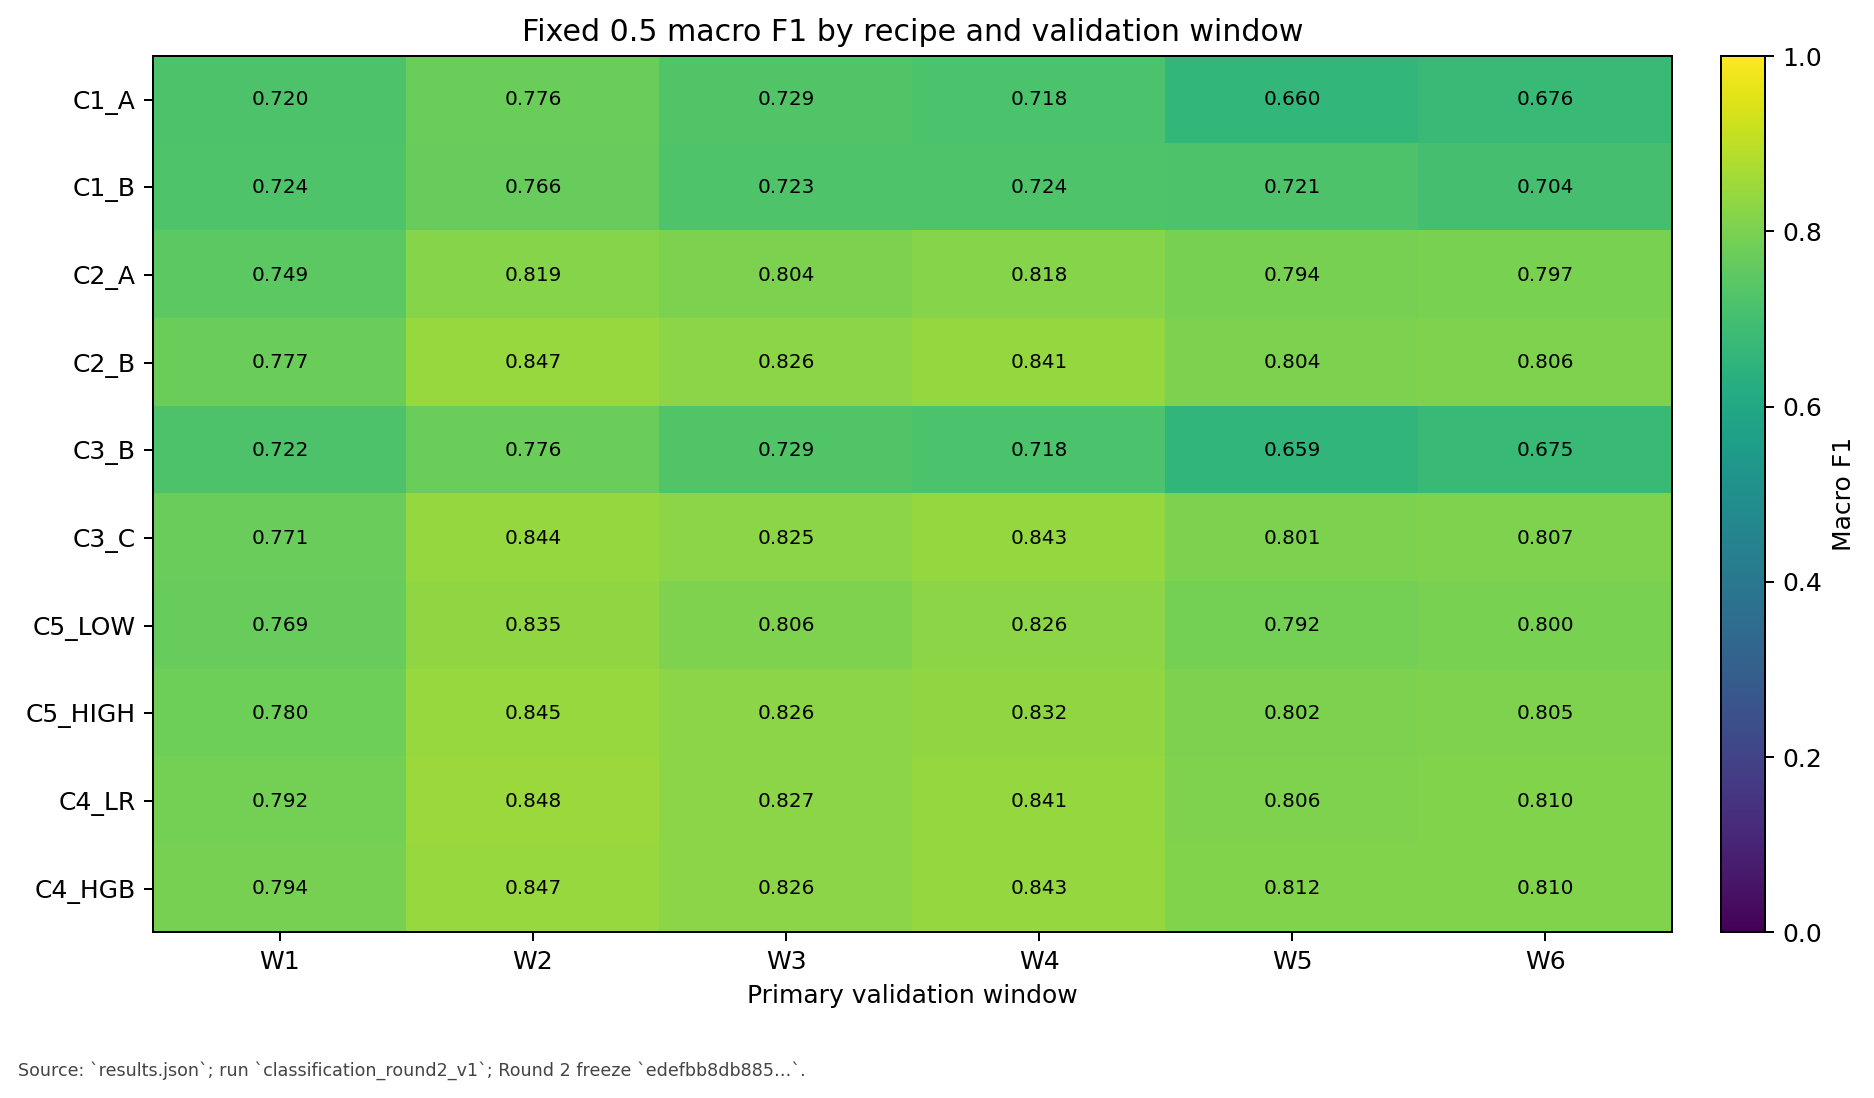

In [3]:
rows=[]
for m in models:
    a=P['fixed_0.5'][m];h=H['fixed_0.5'][m]
    rows.append({'recipe':m,'primary F1':a['metrics']['macro_f1'],'equal-cycle F1':a['equal_cycle_macro_f1'],
       'H12 F1':h['metrics']['macro_f1'],'AP primary':a['metrics']['average_precision'],'Brier primary':a['metrics']['brier_score']})
display(pd.DataFrame(rows).round(4))
display(Image(filename=str(FIG/'classification_round2_fixed_pooled_comparison.png')))
display(Image(filename=str(FIG/'classification_round2_fixed_window_f1_heatmap.png')))

**Interpretasi:** routing adalah hasil terkuat pada cutoff tetap. C4-LR membaik pada seluruh enam primary windows; C4-HGB membaik pada lima, dengan satu penurunan sangat kecil. Kedua route membaik pada kedua H12. Ini belum menghilangkan adaptivity/selection bias atau menetapkan final model.

## C3 — indicator versus joint fitting

C3-B menambahkan indicator ke structured LR; C3-C menghapusnya dari hybrid. Learned structured transform identik dalam setiap history. C3-B hampir tidak mengubah overall performance; menghapus indicator hybrid justru menurunkan missing-stream F1. Indicator saja bukan penjelasan utama gap hybrid terhadap structured models.

,recipe,primary F1,missing F1,present F1,missing mean p
0,C1_A,0.7145,0.7596,0.7106,0.4439
1,C3_B,0.7145,0.7571,0.7107,0.4470
2,C2_B,0.8206,0.7104,0.8286,0.4254
3,C3_C,0.8194,0.7010,0.8283,0.3897


,fit_end,prediction_cycles,n_missing,numeric_coefficient_delta_l2,missing_logit_mean_delta,missing_probability_mean_delta,missing_probability_mean_absolute_change,missing_fixed_label_changes
0,67,"[68, 79]",1375,0.3808,0.0094,-0.0231,0.0673,73


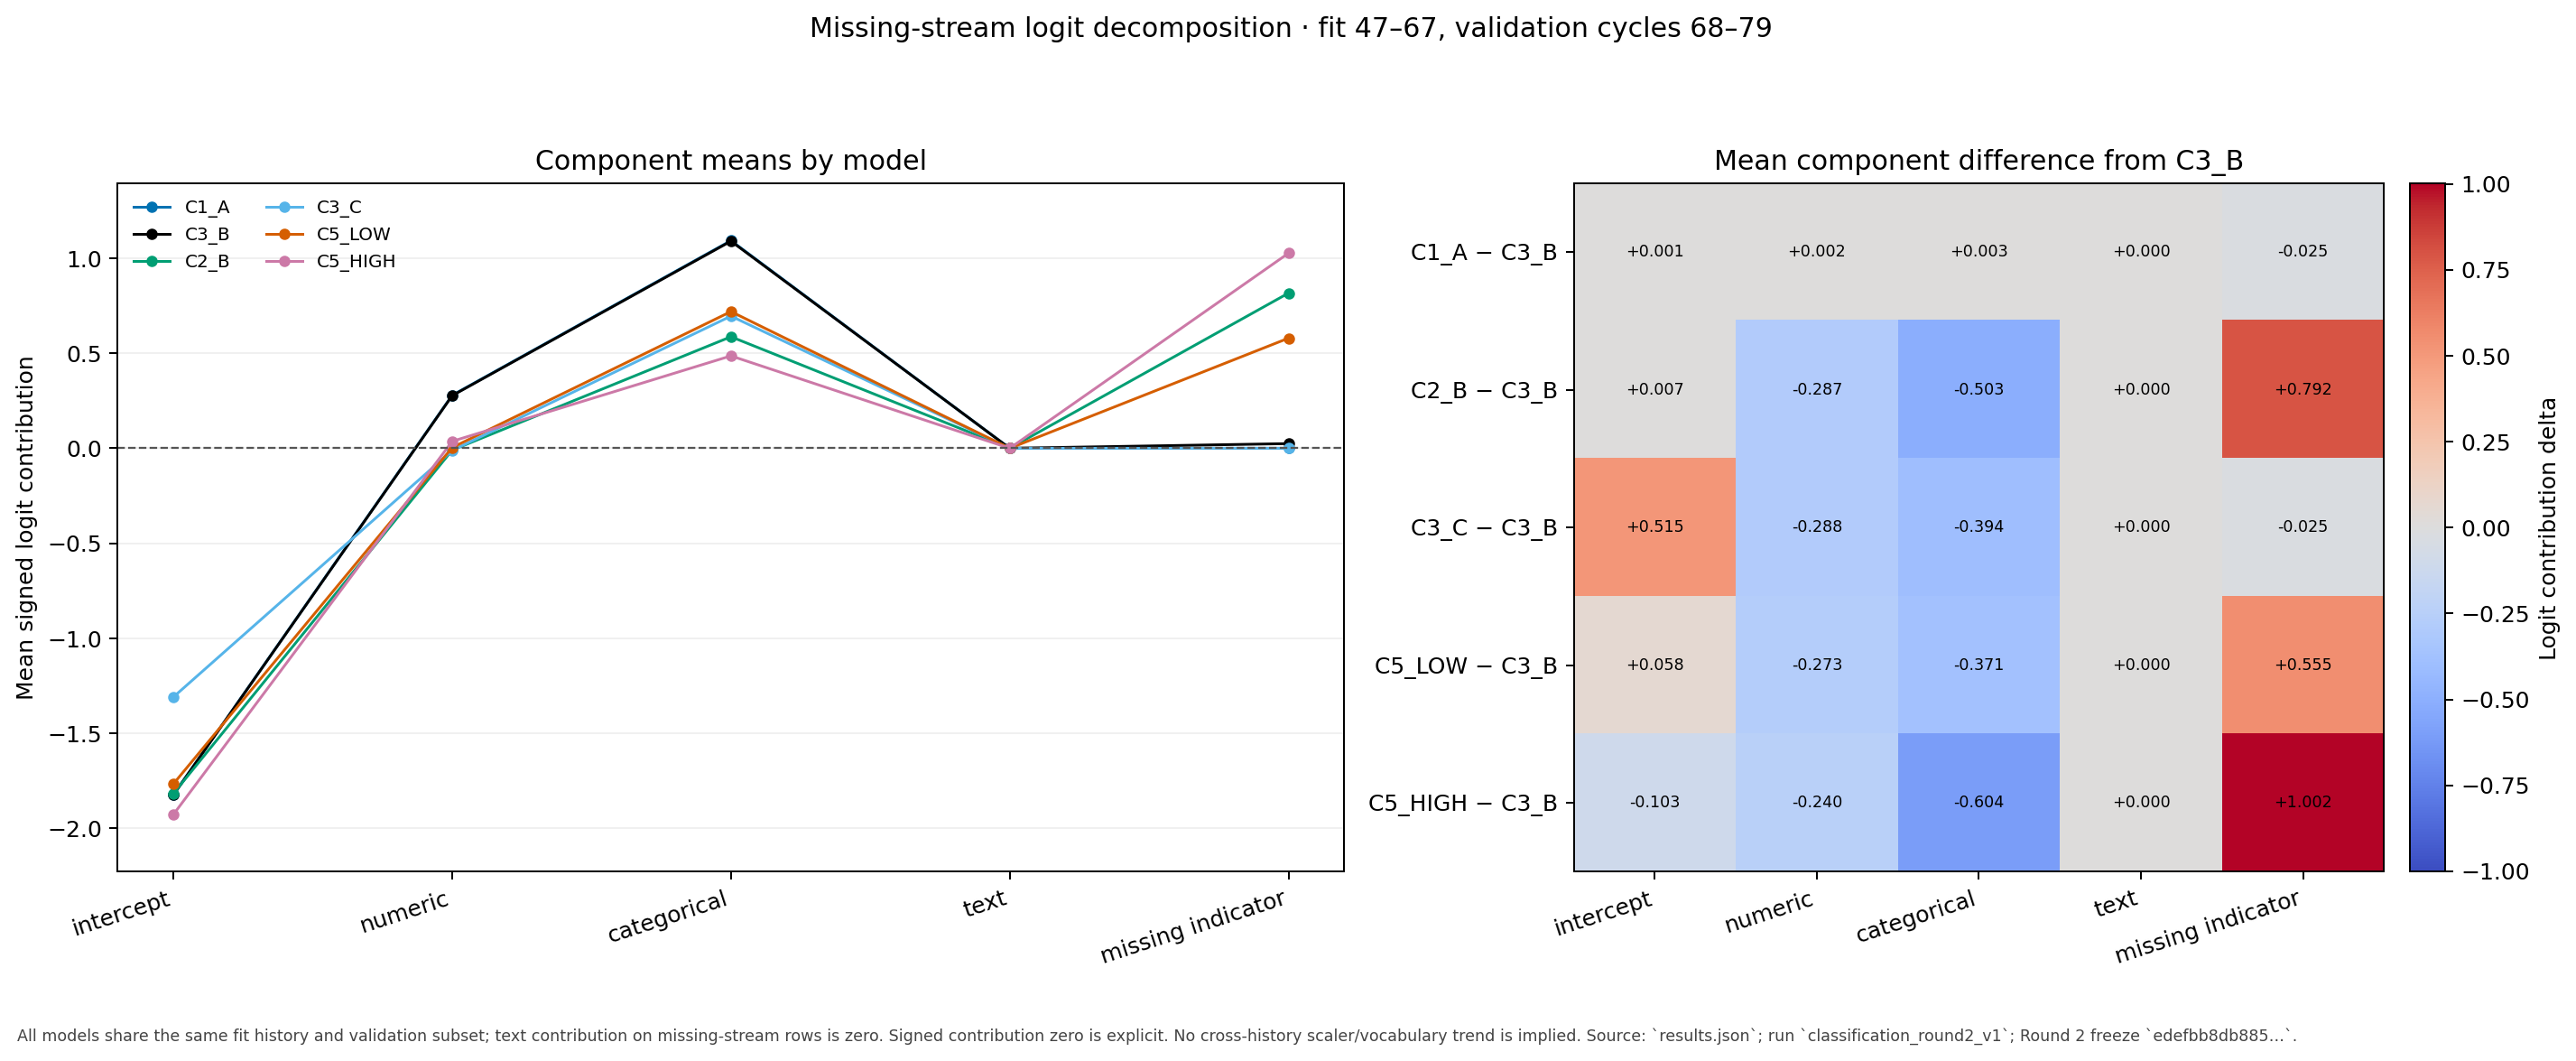

In [4]:
display(pd.DataFrame([{'recipe':m,'primary F1':P['fixed_0.5'][m]['metrics']['macro_f1'],
    'missing F1':P['fixed_0.5'][m]['subgroups']['stream_missing']['macro_f1'],
    'present F1':P['fixed_0.5'][m]['subgroups']['stream_present']['macro_f1'],
    'missing mean p':P['fixed_0.5'][m]['subgroups']['stream_missing']['mean_probability']}
    for m in ['C1_A','C3_B','C2_B','C3_C']]).round(4))
contrasts=[v for v in behavior['within_history_missing_logit_accounting'] if v['fit_end']==67 and v['candidate']=='C2_B' and v['control']=='C3_B']
display(pd.DataFrame(contrasts)[['fit_end','prediction_cycles','n_missing','numeric_coefficient_delta_l2',
 'missing_logit_mean_delta','missing_probability_mean_delta','missing_probability_mean_absolute_change','missing_fixed_label_changes']].round(4))
display(Image(filename=str(FIG/'classification_round2_missing_component_decomposition.png')))

**Interpretasi accounting:** pada history67, C3-B→C2-B mempunyai text contribution tepat nol pada missing rows, tetapi numeric/categorical coefficients, intercept dan indicator berubah. Kontribusi rata-rata saling mengompensasi; mean logit hampir sama tidak berarti probabilitas setiap record atau labelnya sama. Ini net effect joint fitting dengan indicator dan structured transformation yang dipertahankan, bukan causal effect per token. Perbandingan across-history membutuhkan kehati-hatian karena scaler/vocabulary dan prediction ranges berbeda.

## C4 — availability routing

Gate hanya membaca NaN/blank-after-strip. Present memakai C2-B; missing memakai C1-A atau C1-B. Pada cutoff 0,50, present probabilities/labels tetap identik; missing predictions sama dengan branch yang ditetapkan. Pooled F1 dievaluasi ulang dari gabungan predictions.

,recipe,primary F1,H12 F1,missing primary F1,missing H12 F1,present primary F1,FP primary,FN primary
0,C2_B,0.8206,0.7886,0.7104,0.6305,0.8286,2955,3397
1,C4_LR,0.8242,0.7945,0.7596,0.7085,0.8286,2895,3331
2,C4_HGB,0.8255,0.7968,0.7817,0.7450,0.8286,2753,3406


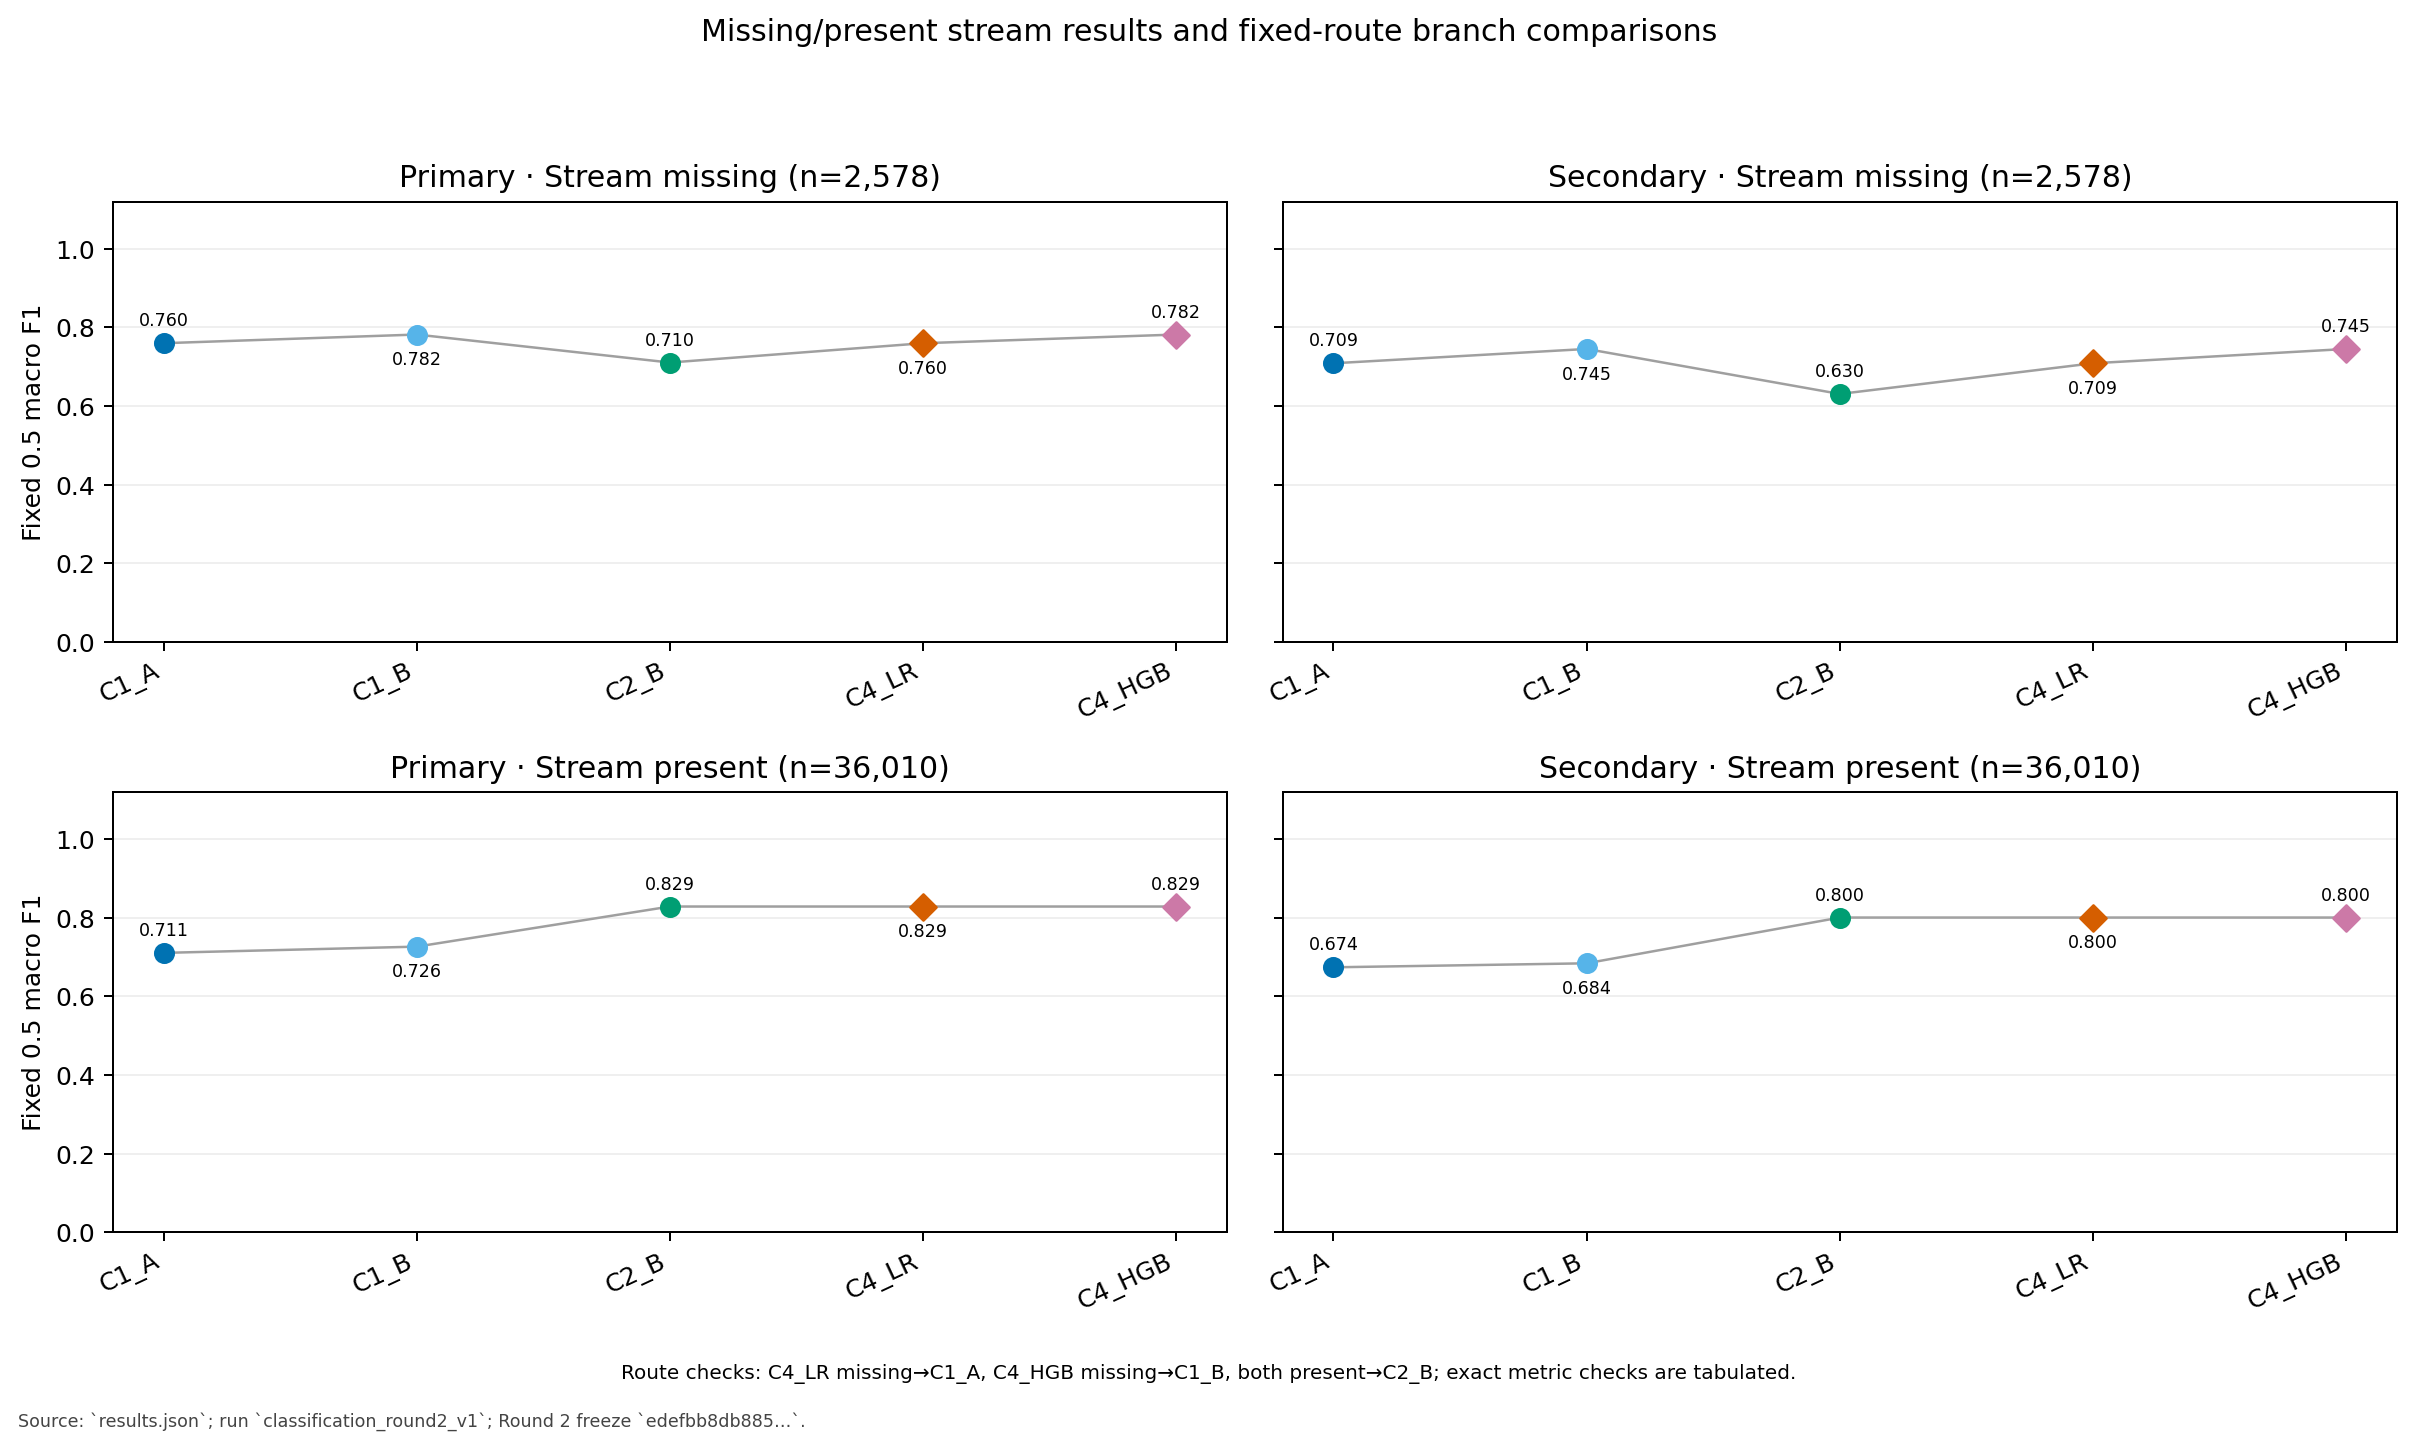

In [5]:
rows=[]
for m in ['C2_B','C4_LR','C4_HGB']:
    a=P['fixed_0.5'][m]; h=H['fixed_0.5'][m]
    rows.append({'recipe':m,'primary F1':a['metrics']['macro_f1'],'H12 F1':h['metrics']['macro_f1'],
      'missing primary F1':a['subgroups']['stream_missing']['macro_f1'],
      'missing H12 F1':h['subgroups']['stream_missing']['macro_f1'],
      'present primary F1':a['subgroups']['stream_present']['macro_f1'],
      'FP primary':a['metrics']['false_positive'],'FN primary':a['metrics']['false_negative']})
display(pd.DataFrame(rows).round(4))
display(Image(filename=str(FIG/'classification_round2_missing_present_f1_and_routes.png')))

**Trade-off:** C4-HGB mengurangi false positives lebih banyak, dengan sedikit tambahan false negatives dibanding hybrid. C4-LR memperbaiki keduanya dan lebih konsisten antarwindow, tetapi pooled gain lebih kecil. Jika route memakai cutoff inner miliknya sendiri, present labels/F1 dapat berubah walaupun present probabilities masih identik. Klaim present-label invariance berlaku pada perbandingan cutoff yang sama.

## C5 — text weights dan regularisasi

Bobot 0,5× dan 2× ditetapkan sebelum hasil dilihat. Semua C tetap 1. Text scaling juga mengubah L2 penalty efektif pada original TF-IDF basis sebesar 1/w²; ini bukan pure feature importance experiment.

In [6]:
audit=json.loads((ROOT/'reports/classification_round2/fit_audits/fit67.json').read_text(encoding='utf-8'))
rows=[]
for m in ['C5_LOW','C2_B','C5_HIGH']:
    c=audit[m]['coefficients'];a=P['fixed_0.5'][m];h=H['fixed_0.5'][m]
    rows.append({'recipe':m,'text weight':c['text_block_weight'],'C':c['model_C'],
      'primary F1':a['metrics']['macro_f1'],'missing F1':a['subgroups']['stream_missing']['macro_f1'],
      'present F1':a['subgroups']['stream_present']['macro_f1'],'H12 F1':h['metrics']['macro_f1'],
      'text coef norm fit67':c['text_coefficient_l2_norm'],'effective original-basis norm':c['text_effective_original_basis_l2_norm']})
display(pd.DataFrame(rows).round(4))

,recipe,text weight,C,primary F1,missing F1,present F1,H12 F1,text coef norm fit67,effective original-basis norm
0,C5_LOW,0.5,1.0,0.8092,0.7225,0.8151,0.7755,43.1605,21.5802
1,C2_B,1.0,1.0,0.8206,0.7104,0.8286,0.7886,47.9254,47.9254
2,C5_HIGH,2.0,1.0,0.8191,0.7245,0.8258,0.7894,51.8439,103.6878


**Interpretasi:** 0,5× memperbaiki missing-stream tetapi merusak present signal dan kalah pada seluruh primary windows. 2× memberi mixed results: sedikit lebih rendah pada primary dan sedikit lebih tinggi pada pooled H12; kenaikan H12 tidak merata pada dua windows. Tidak ada alasan dari putaran ini untuk memperluas weight grid.

## C6 — threshold transfer

Fixed0,50; pooled-inner lama; half-shrink menuju0,50; dan equal-cycle-inner. Semuanya memakai empat cycle inner sebelum outer evaluation. Routes memilih satu cutoff dari gabungan branch inner probabilities, bukan mewarisi cutoff hybrid. Grid/tie/fallback dibekukan; tidak ada outer-label optimization atau calibration fit.

primary


,recipe,fixed_0.5,inner_pooled,inner_shrink50,inner_equal_cycle
0,C2_B,0.8206,0.8188,0.8202,0.8190
1,C4_LR,0.8242,0.8231,0.8243,0.8248
2,C4_HGB,0.8255,0.8236,0.8254,0.8236
3,C5_LOW,0.8092,0.8092,0.8105,0.8078
4,C5_HIGH,0.8191,0.8197,0.8181,0.8197


H12


,recipe,fixed_0.5,inner_pooled,inner_shrink50,inner_equal_cycle
0,C2_B,0.7886,0.7924,0.7903,0.7925
1,C4_LR,0.7945,0.7985,0.7965,0.8021
2,C4_HGB,0.7968,0.7998,0.7985,0.7998
3,C5_LOW,0.7755,0.7856,0.7817,0.7856
4,C5_HIGH,0.7894,0.7933,0.7910,0.7933


,policy,threshold,inner_prevalence,outer_prevalence,inner_mean_probability,outer_mean_probability,positive_prediction_rate,outer_f1,class1_precision,class1_recall
0,fixed_0.5,0.50,0.4222,0.4542,0.3408,0.4459,0.4473,0.8471,0.8385,0.8257
1,inner_pooled,0.34,0.4222,0.4542,0.3408,0.4459,0.5455,0.8233,0.7544,0.9061
2,inner_shrink50,0.42,0.4222,0.4542,0.3408,0.4459,0.4944,0.8396,0.7975,0.8681


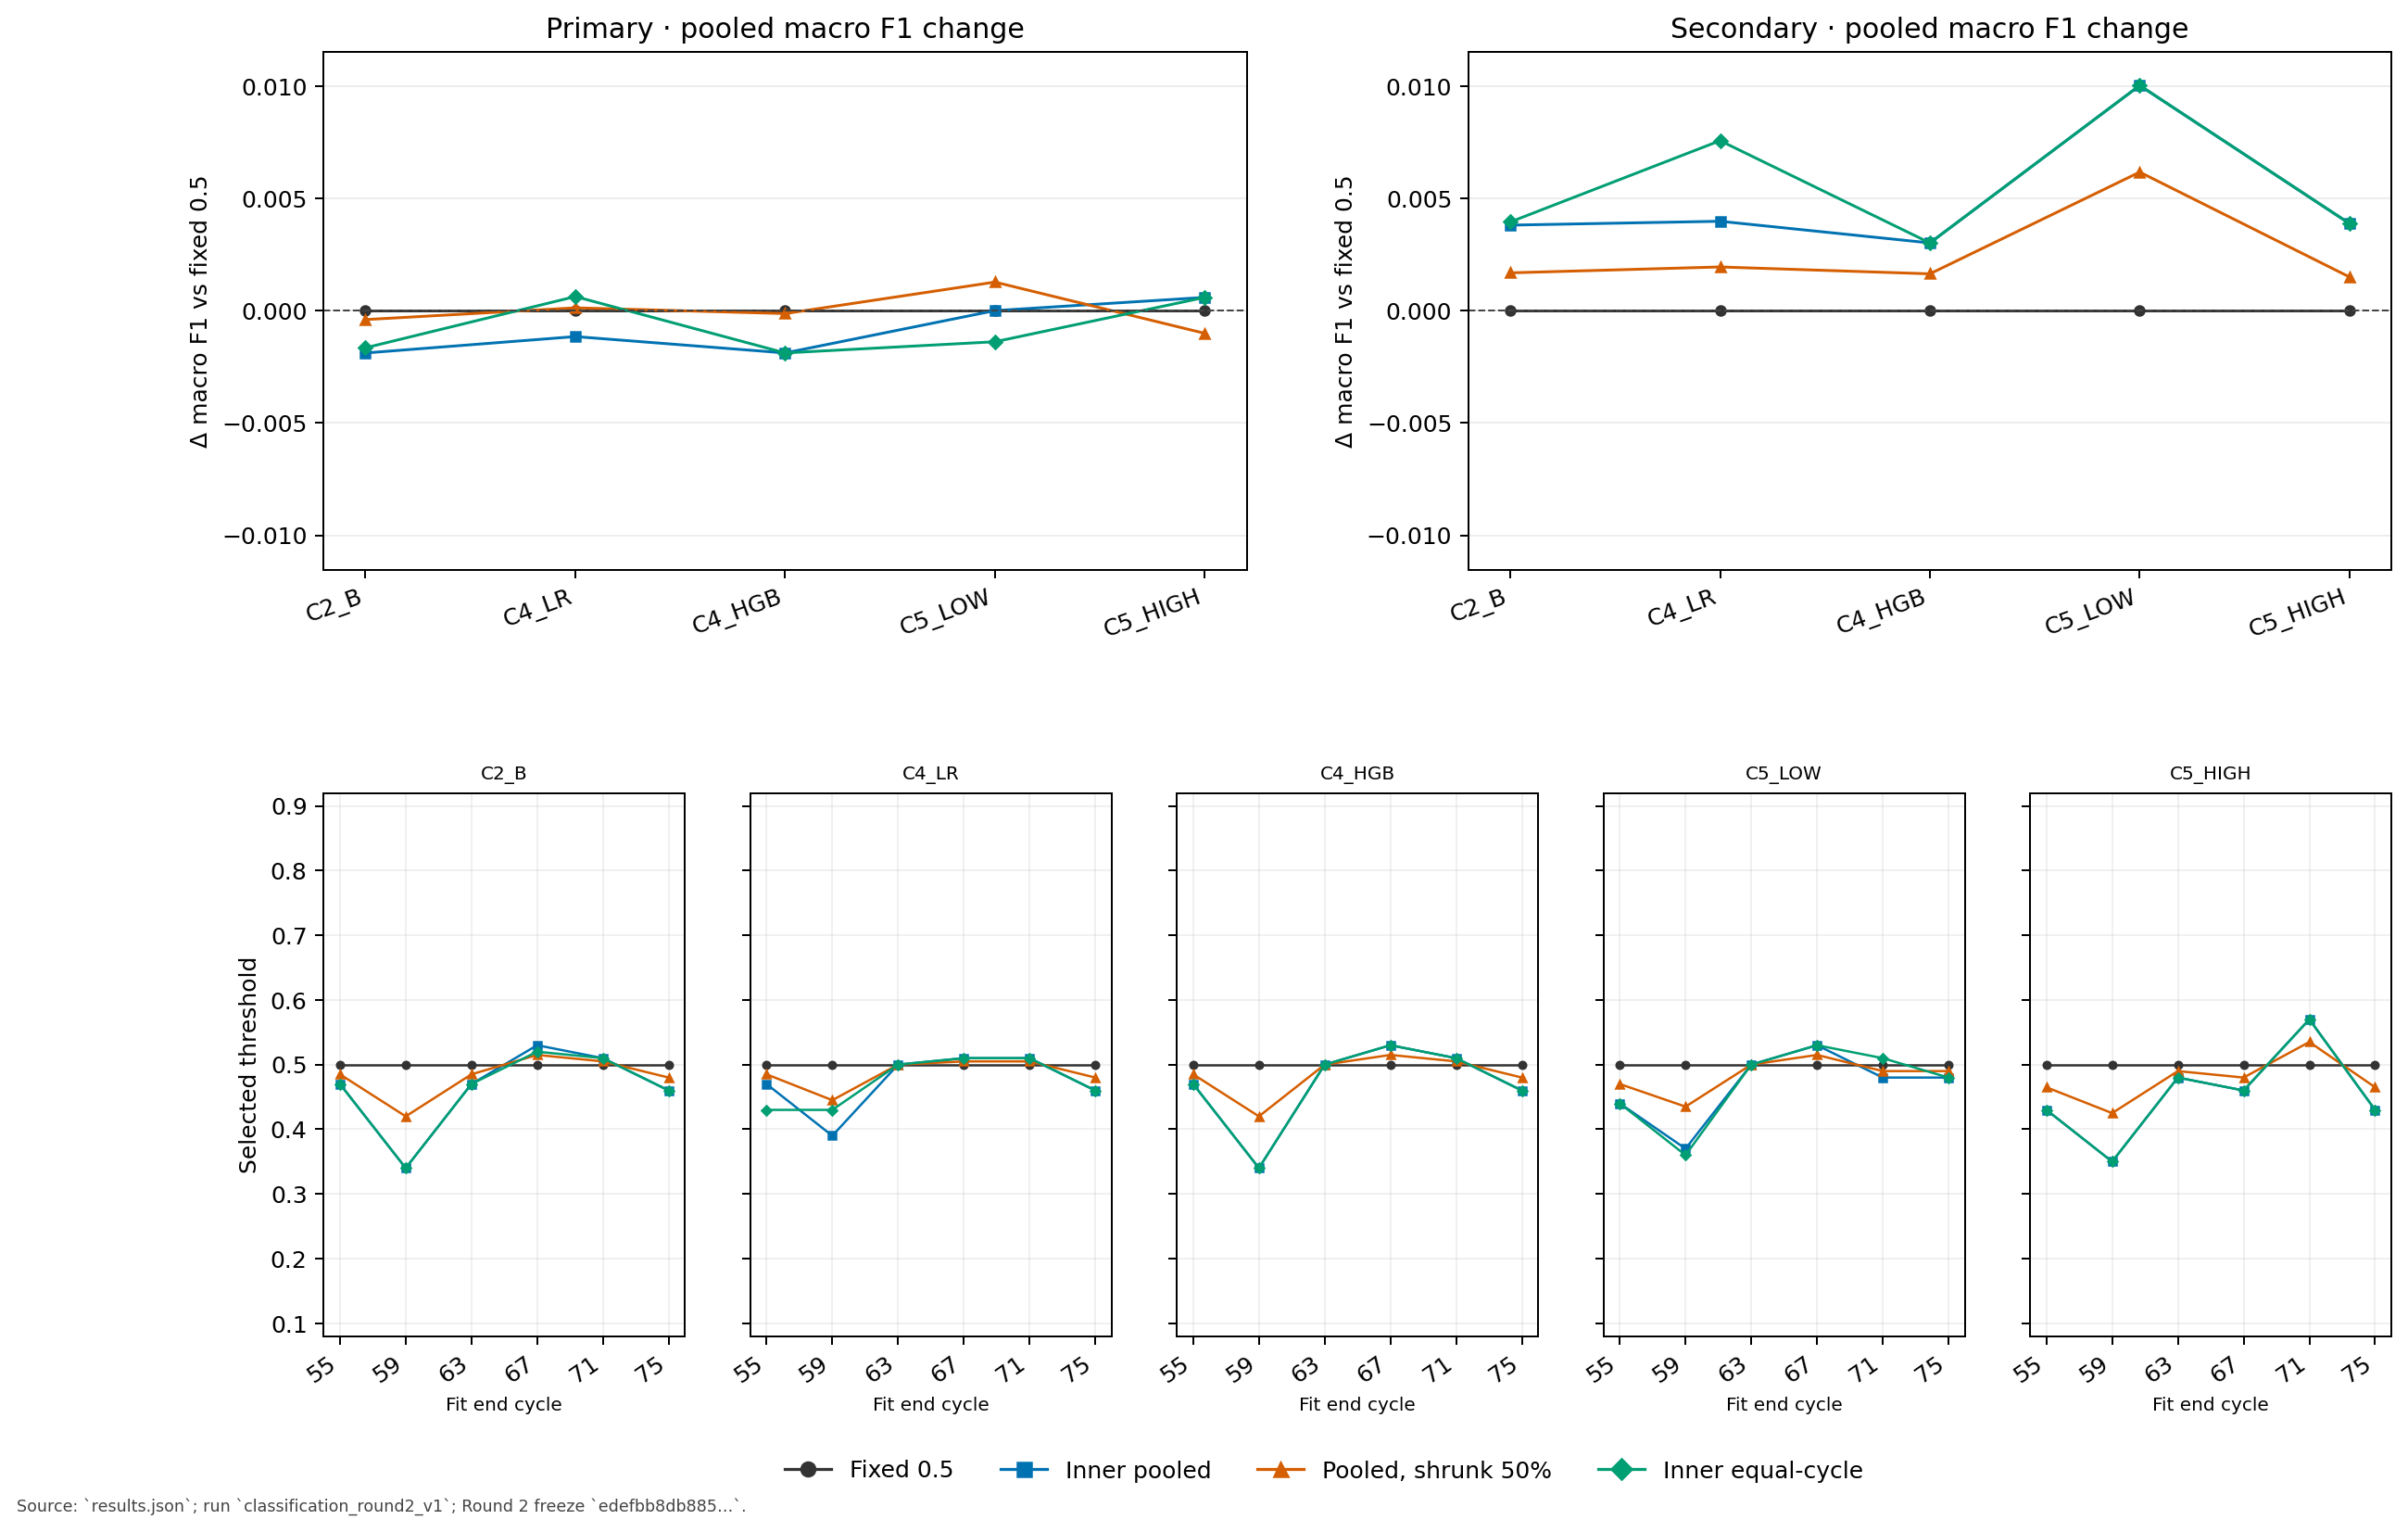

In [7]:
focus=['C2_B','C4_LR','C4_HGB','C5_LOW','C5_HIGH']
for family,source in [('primary',P),('H12',H)]:
    print(family)
    display(pd.DataFrame([{'recipe':m,**{p:source[p][m]['metrics']['macro_f1'] for p in protocol['threshold_policies']}} for m in focus]).round(4))
example=[a for a in behavior['threshold_transfer'] if a['model']=='C2_B' and a['window']=='W2' and a['policy'] in ['fixed_0.5','inner_pooled','inner_shrink50']]
display(pd.DataFrame(example)[['policy','threshold','inner_prevalence','outer_prevalence','inner_mean_probability',
 'outer_mean_probability','positive_prediction_rate','outer_f1','class1_precision','class1_recall']].round(4))
display(Image(filename=str(FIG/'classification_round2_policy_effects.png')))

**Interpretasi:** policy universal belum ditemukan. Half-shrink mengurangi sebagian kerusakan transfer tetapi tidak mengalahkan fixed untuk hybrid. C4-LR equal-cycle mencapai pooled H12 tertinggi, terutama dari H12_E; late-window gain jauh lebih kecil. Pada W2 hybrid, prevalence naik, tetapi mean probability juga naik setelah refit; cutoff lama0,34 mengalokasikan terlalu banyak positives. Ranking/AP tetap sama untuk semua policies pada model/window yang sama, sehingga perbedaan F1 policy murni berasal dari allocation, bukan model ranking baru.

## Temporal dan subgroup behavior

Per-cycle F1 dan positive prediction rates tetap perlu dibaca bersama prevalence. Routing tidak menghapus gap horizon; subgroup scores juga dipengaruhi prevalence dan support. Unknown/missing groups dapat overlap.

,recipe,group,n,F1,precision1,recall1,FP,FN
0,C2_B,EF0,26048,0.8290,0.7882,0.7464,1706,2156
1,C2_B,EF1,12540,0.7982,0.7723,0.7735,1249,1241
2,C2_B,stream_missing,2578,0.7104,0.6362,0.7550,474,269
3,C2_B,stream_present,36010,0.8286,0.7972,0.7572,2481,3128
4,C2_B,all_codes_known_nonmissing,14452,0.8161,0.7652,0.7086,920,1233
5,C2_B,any_unseen_code,18645,0.8081,0.7869,0.7904,1789,1752
6,C4_LR,EF0,26048,0.8330,0.7945,0.7509,1652,2118
7,C4_LR,EF1,12540,0.8011,0.7743,0.7786,1243,1213
8,C4_LR,stream_missing,2578,0.7596,0.6837,0.8151,414,203
9,C4_LR,stream_present,36010,0.8286,0.7972,0.7572,2481,3128


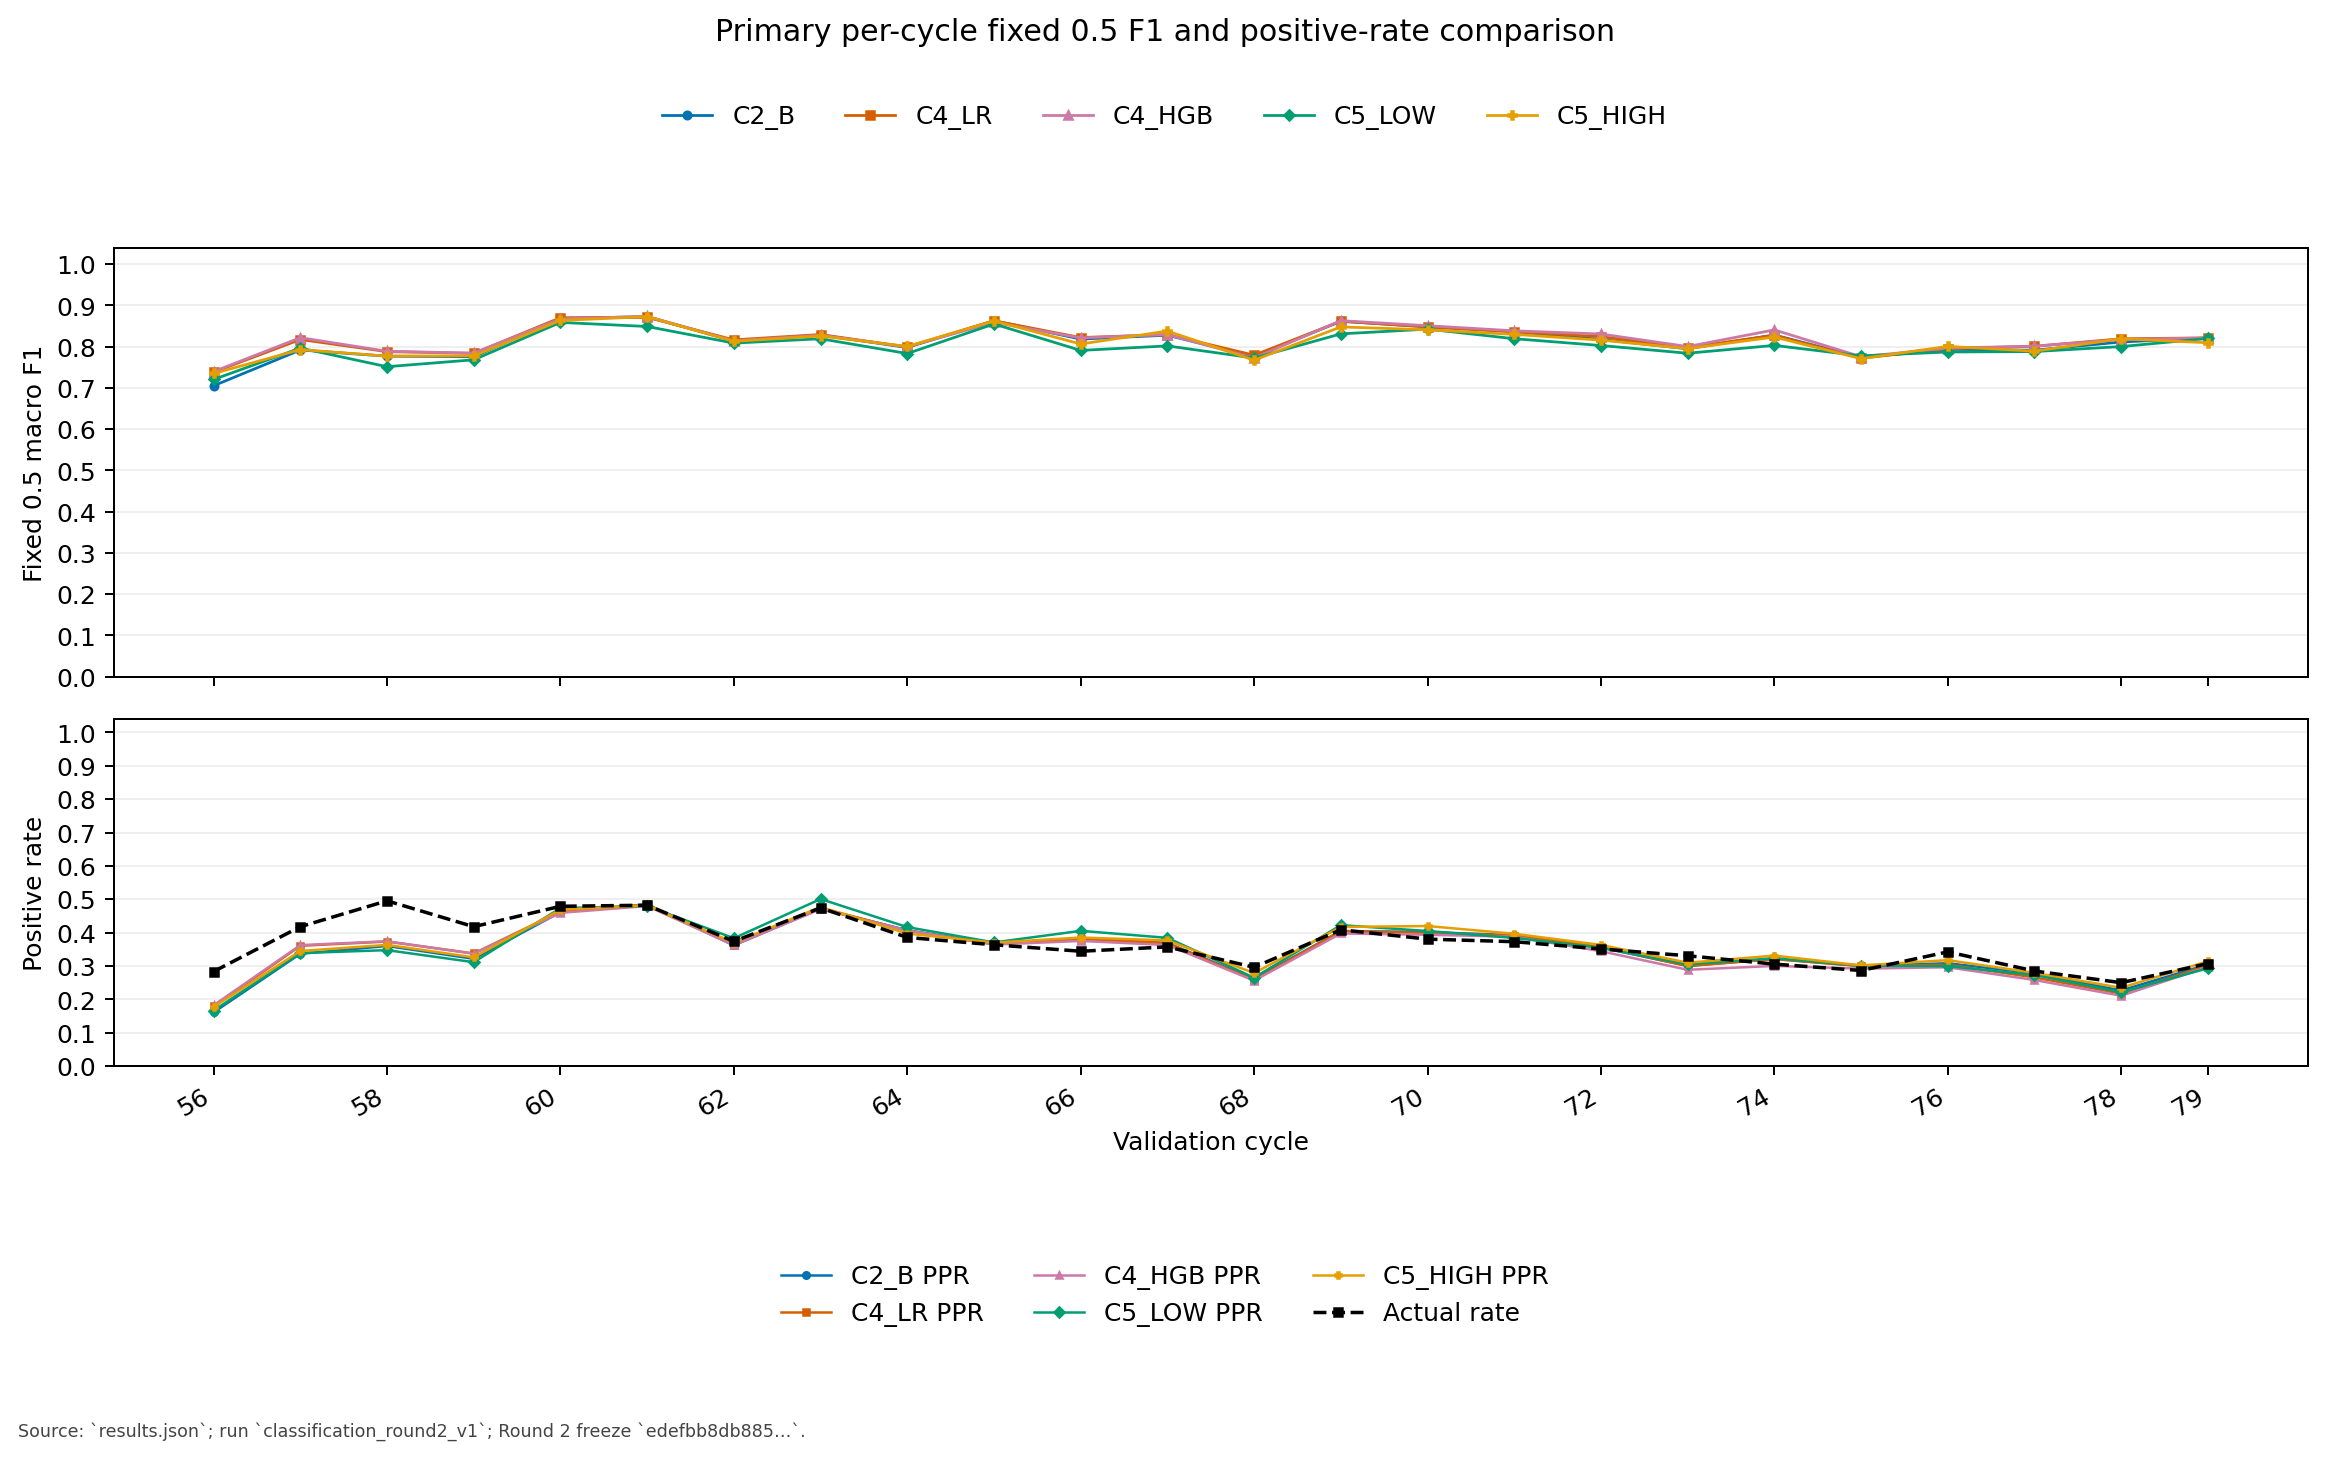

In [8]:
rows=[]
for m in ['C2_B','C4_LR','C4_HGB']:
    a=P['fixed_0.5'][m]
    for group in ['EF0','EF1','stream_missing','stream_present','all_codes_known_nonmissing','any_unseen_code']:
        g=a['subgroups'][group]
        rows.append({'recipe':m,'group':group,'n':g['n'],'F1':g['macro_f1'],'precision1':g['per_class'][1]['precision'],
          'recall1':g['per_class'][1]['recall'],'FP':g['false_positive'],'FN':g['false_negative']})
display(pd.DataFrame(rows).round(4))
display(Image(filename=str(FIG/'classification_round2_fixed_cycle_f1_ppr.png')))

## Takeaways — berhenti untuk review

Missing-stream performance membaik melalui fallback; single-hybrid issue belum selesai melalui indicator/weights saja. C4-HGB fixed menjadi provisional leader, C4-LR penting sebagai pembanding recall/stability, dan C2-B tetap baseline. Jangan langsung mengunci salah satu sebagai final model.

Round3 yang belum dijalankan: validasi robustness route dengan acceptance rules baru; satu past-only probability/rank-allocation transfer policy jika disetujui; diagnosis conditional ranking pada missing rows. TP1 Phase11 memotivasi joint-fitting/missing checks, Phase14 memisahkan ranking dari allocation; recipe keduanya tidak disalin.

Untuk Regression, prioritas berikutnya tetap controlled feature/history attribution R1-D dan H12 sensitivity sebelum final selection. Tidak ada Regression Round2 pada milestone ini.

QA/receipts dan pembahasan lengkap: `reports/classification_round2/FINDINGS.md`, `verification.json`, `behavior_diagnostics.json`, `comparison_tables.md`. Reproduksi: `docs/CLASSIFICATION_ROUND2.md`. **STOP setelah Round2 untuk review pengguna.** Tidak ada Round3, final model, complex ensemble, Test prediction atau Kaggle submission.